In [49]:
# # FINAURA – Gold Data Preprocessing

# This notebook performs complete preprocessing of the Gold price dataset.

# ## Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Analysis
# 6. Date Sorting
# 7. Price Validation
# 8. Return Calculation
# 9. Log Return Calculation
# 10. Intraday Return
# 11. Price Range
# 12. Moving Averages
# 13. Rolling Volatility
# 14. Momentum
# 15. Drawdown
# 16. Volume Features
# 17. Next 5-Day Volatility Target
# 18. Leakage Check
# 19. Final Validation
# 20. Data Visualization
# 21. Export Processed Dataset

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [51]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "gold_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "gold_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\gold_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_processed.csv


In [52]:
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 2483
Columns: 7


,Date,Adj Close,Close,High,Low,Open,Volume
0,2017-01-03,1160.4000,1160.4000,1160.8000,1146.5000,1155.2000,52
1,2017-01-04,1163.8000,1163.8000,1165.0000,1156.3000,1156.3000,36
2,2017-01-05,1179.7000,1179.7000,1183.3000,1171.5000,1172.0000,500
3,2017-01-06,1171.9000,1171.9000,1176.5000,1171.9000,1176.5000,16
4,2017-01-09,1183.5000,1183.5000,1183.6000,1173.0000,1173.9000,62


In [53]:
print("Current working directory:", Path.cwd())
print("Input file:", INPUT_FILE.resolve())
print("Output file:", OUTPUT_FILE.resolve())

print("Raw latest date:", df["Date"].max())
print("Raw rows:", len(df))

Current working directory: c:\Users\madhu\OneDrive\Documents\FINAURA\notebooks
Input file: C:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\gold_raw.csv
Output file: C:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_processed.csv
Raw latest date: 2026-11-13
Raw rows: 2483


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2483 non-null   object 
 1   Adj Close  2483 non-null   float64
 2   Close      2483 non-null   float64
 3   High       2483 non-null   float64
 4   Low        2483 non-null   float64
 5   Open       2483 non-null   float64
 6   Volume     2483 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 135.9+ KB


In [55]:
df.describe()

,Adj Close,Close,High,Low,Open,Volume
count,2483.0000,2483.0000,2483.0000,2483.0000,2483.0000,2483.0000
mean,2132.1118,2132.1118,2148.9081,2114.5341,2131.9961,130542.4289
std,986.2121,986.2121,1001.8935,969.7526,986.3053,109382.5739
min,1160.4000,1160.4000,1160.8000,1146.5000,1155.2000,0.0000
25%,1396.4500,1396.4500,1397.2500,1388.2000,1392.8000,373.0000
50%,1826.2000,1826.2000,1835.9000,1813.0000,1825.4000,151434.0000
75%,2350.0500,2350.0500,2373.8000,2334.9501,2348.2500,206269.0000
max,5318.3999,5318.3999,5586.2002,5272.8999,5415.7002,570055.0000


In [56]:
print(df.columns.tolist())

['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [57]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


In [58]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [59]:
numeric_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume"
]

if "adj_close" in df.columns:
    numeric_columns.append("adj_close")

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2483 entries, 0 to 2482
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       2483 non-null   datetime64[ns]
 1   adj_close  2483 non-null   float64       
 2   close      2483 non-null   float64       
 3   high       2483 non-null   float64       
 4   low        2483 non-null   float64       
 5   open       2483 non-null   float64       
 6   volume     2483 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 135.9 KB


In [60]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
adj_close,0,0.0000
close,0,0.0000
high,0,0.0000
low,0,0.0000
open,0,0.0000
volume,0,0.0000


In [61]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

Duplicate rows: 0
Duplicate dates: 0


In [62]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["date"],
    keep="first"
)

print(
    "Rows after duplicate removal:",
    len(df)
)

Rows after duplicate removal: 2483


In [63]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

Invalid dates: 0


In [64]:
df = df.dropna(
    subset=["date"]
)

In [65]:
df = df.sort_values(
    "date"
).reset_index(drop=True)

df.head()

,date,adj_close,close,high,low,open,volume
0,2017-01-03,1160.4000,1160.4000,1160.8000,1146.5000,1155.2000,52
1,2017-01-04,1163.8000,1163.8000,1165.0000,1156.3000,1156.3000,36
2,2017-01-05,1179.7000,1179.7000,1183.3000,1171.5000,1172.0000,500
3,2017-01-06,1171.9000,1171.9000,1176.5000,1171.9000,1176.5000,16
4,2017-01-09,1183.5000,1183.5000,1183.6000,1173.0000,1173.9000,62


In [66]:
print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

Start date: 2017-01-03 00:00:00
End date: 2026-11-13 00:00:00


In [67]:
core_columns = [
    "open",
    "high",
    "low",
    "close"
]

print(
    df[core_columns]
    .isnull()
    .sum()
)

open     0
high     0
low      0
close    0
dtype: int64


In [68]:
df = df.dropna(
    subset=core_columns
).reset_index(drop=True)

print(
    "Rows remaining:",
    len(df)
)

Rows remaining: 2483


In [69]:
for col in core_columns:

    invalid = (
        df[col] <= 0
    ).sum()

    print(
        f"{col}: {invalid} invalid values"
    )

open: 0 invalid values
high: 0 invalid values
low: 0 invalid values
close: 0 invalid values


In [70]:
for col in core_columns:
    df = df[df[col] > 0].copy()

In [71]:
invalid_ohlc = (
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"]) |
    (df["high"] < df["low"])
)

print(
    "Invalid OHLC rows:",
    invalid_ohlc.sum()
)

Invalid OHLC rows: 0


In [72]:
df = df[
    ~invalid_ohlc
].copy()

print(
    "Rows after OHLC validation:",
    len(df)
)

Rows after OHLC validation: 2483


In [73]:
if "volume" in df.columns:

    print(
        "Negative volume:",
        (df["volume"] < 0).sum()
    )

    df = df[
        df["volume"] >= 0
    ].copy()

Negative volume: 0


In [74]:
df["daily_return"] = (
    df["close"].pct_change()
)

df[
    [
        "date",
        "close",
        "daily_return"
    ]
].head(10)

,date,close,daily_return
0,2017-01-03,1160.4000,NaN
1,2017-01-04,1163.8000,0.0029
2,2017-01-05,1179.7000,0.0137
3,2017-01-06,1171.9000,-0.0066
4,2017-01-09,1183.5000,0.0099
5,2017-01-10,1184.2000,0.0006
6,2017-01-11,1195.6000,0.0096
7,2017-01-12,1198.9000,0.0028
8,2017-01-13,1195.3000,-0.0030
9,2017-01-17,1212.0000,0.0140


In [75]:
df["log_return"] = (
    np.log(
        df["close"] /
        df["close"].shift(1)
    )
)

df[
    [
        "date",
        "close",
        "log_return"
    ]
].head(10)

,date,close,log_return
0,2017-01-03,1160.4000,NaN
1,2017-01-04,1163.8000,0.0029
2,2017-01-05,1179.7000,0.0136
3,2017-01-06,1171.9000,-0.0066
4,2017-01-09,1183.5000,0.0098
5,2017-01-10,1184.2000,0.0006
6,2017-01-11,1195.6000,0.0096
7,2017-01-12,1198.9000,0.0028
8,2017-01-13,1195.3000,-0.0030
9,2017-01-17,1212.0000,0.0139


In [76]:
df["intraday_return"] = (
    (df["close"] - df["open"])
    / df["open"]
)

df[
    [
        "date",
        "intraday_return"
    ]
].head()

,date,intraday_return
0,2017-01-03,0.0045
1,2017-01-04,0.0065
2,2017-01-05,0.0066
3,2017-01-06,-0.0039
4,2017-01-09,0.0082


In [77]:
df["price_range"] = (
    (df["high"] - df["low"])
    / df["close"]
)

df[
    [
        "date",
        "price_range"
    ]
].head()

,date,price_range
0,2017-01-03,0.0123
1,2017-01-04,0.0075
2,2017-01-05,0.0100
3,2017-01-06,0.0039
4,2017-01-09,0.0090


In [78]:
for window in [5, 10, 20, 50]:

    df[f"ma_{window}"] = (
        df["close"]
        .rolling(window)
        .mean()
    )

In [79]:
df[
    [
        "date",
        "close",
        "ma_5",
        "ma_20",
        "ma_50"
    ]
].tail(10)

,date,close,ma_5,ma_20,ma_50
2473,2026-11-02,3969.6001,4005.2200,4105.6800,4280.5780
2474,2026-11-03,3940.3999,3978.3800,4093.3450,4265.4300
2475,2026-11-04,4073.0000,3982.6600,4089.9600,4253.0000
2476,2026-11-05,4113.5000,3999.0800,4087.7850,4242.2040
2477,2026-11-06,4074.8999,4034.2800,4080.7150,4230.4220
2478,2026-11-09,4114.5000,4063.2600,4076.9100,4222.1140
2479,2026-11-10,4030.2000,4081.2200,4069.5550,4213.0880
2480,2026-11-11,4000.5000,4066.7200,4064.1850,4205.1700
2481,2026-11-12,3885.3000,4021.0800,4049.9450,4194.5840
2482,2026-11-13,3881.3000,3982.3600,4034.9550,4181.4120


In [80]:
for window in [5, 10, 20]:

    df[f"volatility_{window}d"] = (
        df["log_return"]
        .rolling(window)
        .std()
        * np.sqrt(252)
    )

In [81]:
df[
    [
        "date",
        "volatility_5d",
        "volatility_10d",
        "volatility_20d"
    ]
].tail(10)

,date,volatility_5d,volatility_10d,volatility_20d
2473,2026-11-02,0.3092,0.2414,0.2052
2474,2026-11-03,0.2891,0.2417,0.2027
2475,2026-11-04,0.4054,0.3083,0.2371
2476,2026-11-05,0.4052,0.2915,0.2396
2477,2026-11-06,0.2828,0.2871,0.2350
2478,2026-11-09,0.2719,0.2885,0.2378
2479,2026-11-10,0.3275,0.3060,0.2479
2480,2026-11-11,0.2099,0.3068,0.2426
2481,2026-11-12,0.2338,0.3376,0.2536
2482,2026-11-13,0.2456,0.2941,0.2528


In [82]:
df["momentum_5d"] = (
    df["close"] /
    df["close"].shift(5) - 1
)

df["momentum_20d"] = (
    df["close"] /
    df["close"].shift(20) - 1
)

df[
    [
        "date",
        "momentum_5d",
        "momentum_20d"
    ]
].tail()

,date,momentum_5d,momentum_20d
2478,2026-11-09,0.0365,-0.0182
2479,2026-11-10,0.0228,-0.0352
2480,2026-11-11,-0.0178,-0.0261
2481,2026-11-12,-0.0555,-0.0683
2482,2026-11-13,-0.0475,-0.0717


In [83]:
df["running_max"] = (
    df["close"].cummax()
)

df["drawdown"] = (
    df["close"] /
    df["running_max"] - 1
)

df.drop(
    columns=["running_max"],
    inplace=True
)

df[
    [
        "date",
        "close",
        "drawdown"
    ]
].tail()

,date,close,drawdown
2478,2026-11-09,4114.5000,-0.2264
2479,2026-11-10,4030.2000,-0.2422
2480,2026-11-11,4000.5000,-0.2478
2481,2026-11-12,3885.3000,-0.2695
2482,2026-11-13,3881.3000,-0.2702


In [84]:
if "volume" in df.columns:

    df["volume_ma_20"] = (
        df["volume"]
        .rolling(20)
        .mean()
    )

    df["volume_ratio"] = (
        df["volume"] /
        df["volume_ma_20"]
    )

    df[
        [
            "date",
            "volume",
            "volume_ma_20",
            "volume_ratio"
        ]
    ].tail()

In [85]:
future_returns = pd.concat(
    [
        df["log_return"].shift(-i)
        for i in range(1, 6)
    ],
    axis=1
)

future_returns.columns = [
    f"_future_return_{i}"
    for i in range(1, 6)
]

df["target_5d_volatility"] = (
    future_returns.std(axis=1)
    * np.sqrt(252)
)

future_returns.head()

,_future_return_1,_future_return_2,_future_return_3,_future_return_4,_future_return_5
0,0.0029,0.0136,-0.0066,0.0098,0.0006
1,0.0136,-0.0066,0.0098,0.0006,0.0096
2,-0.0066,0.0098,0.0006,0.0096,0.0028
3,0.0098,0.0006,0.0096,0.0028,-0.0030
4,0.0006,0.0096,0.0028,-0.0030,0.0139


In [86]:
df[
    [
        "date",
        "close",
        "volatility_20d",
        "target_5d_volatility"
    ]
].tail(15)

,date,close,volatility_20d,target_5d_volatility
2468,2026-10-26,4038.3999,0.1532,0.3092
2469,2026-10-27,4074.6001,0.1571,0.2891
2470,2026-10-28,4051.6001,0.1574,0.4054
2471,2026-10-29,4031.3999,0.1565,0.4052
2472,2026-10-30,3898.8999,0.1908,0.2828
2473,2026-11-02,3969.6001,0.2052,0.2719
2474,2026-11-03,3940.3999,0.2027,0.3275
2475,2026-11-04,4073.0000,0.2371,0.2099
2476,2026-11-05,4113.5000,0.2396,0.2338
2477,2026-11-06,4074.8999,0.2350,0.2456


In [87]:
target = "target_5d_volatility"

feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown"
]

if "volume" in df.columns:
    feature_columns.extend([
        "volume",
        "volume_ma_20",
        "volume_ratio"
    ])

print(
    "Number of features:",
    len(feature_columns)
)

print(
    "Target:",
    target
)

print(
    "Target included in features:",
    target in feature_columns
)

Number of features: 21
Target: target_5d_volatility
Target included in features: False


In [88]:
print(
    "Temporary future-return columns were stored separately."
)

print(
    "Target calculation completed successfully."
)

Temporary future-return columns were stored separately.
Target calculation completed successfully.


In [89]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 183


In [90]:
df = df.dropna().reset_index(
    drop=True
)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [91]:
print("========== FINAL DATASET ==========")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate dates:",
    df.duplicated(
        subset=["date"]
    ).sum()
)

========== FINAL DATASET ==========
Rows: 2432
Columns: 24
Start date: 2017-03-15 00:00:00
End date: 2026-11-11 00:00:00
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0


In [92]:
for i, col in enumerate(
    df.columns,
    1
):
    print(
        i,
        "-",
        col
    )

1 - date
2 - adj_close
3 - close
4 - high
5 - low
6 - open
7 - volume
8 - daily_return
9 - log_return
10 - intraday_return
11 - price_range
12 - ma_5
13 - ma_10
14 - ma_20
15 - ma_50
16 - volatility_5d
17 - volatility_10d
18 - volatility_20d
19 - momentum_5d
20 - momentum_20d
21 - drawdown
22 - volume_ma_20
23 - volume_ratio
24 - target_5d_volatility


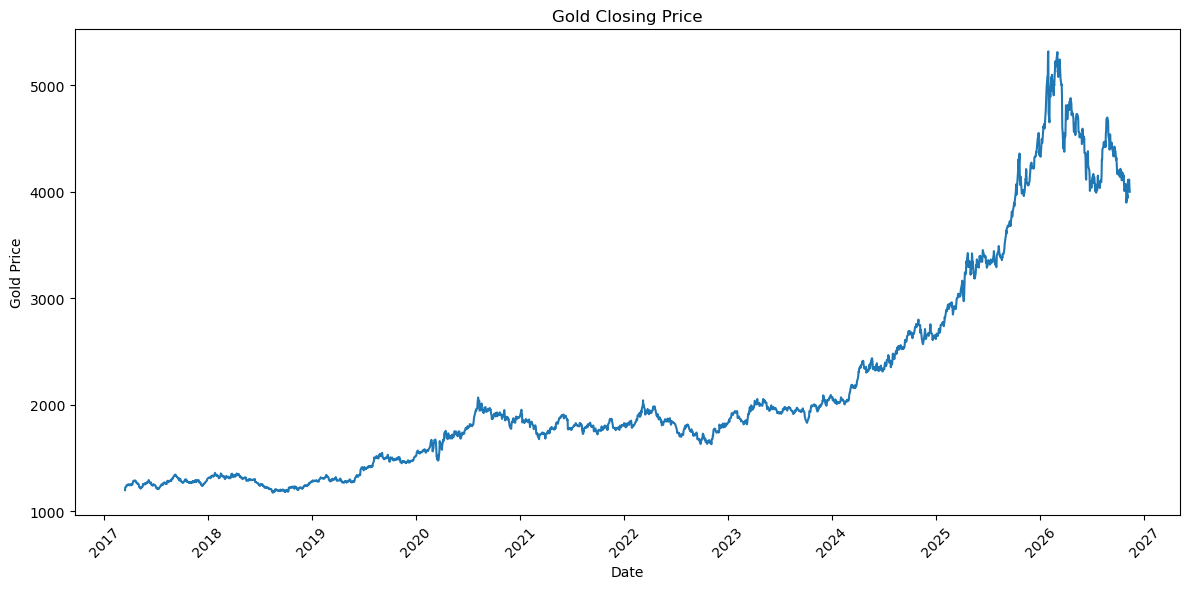

In [93]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["close"]
)

plt.title(
    "Gold Closing Price"
)

plt.xlabel("Date")
plt.ylabel("Gold Price")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [94]:
print("Rows before saving:", len(df))
print("Latest processed date:", df["date"].max())
print("Missing values:", df.isnull().sum().sum())

print("\nLast 10 dates:")
print(df[["date", "close"]].tail(10))

Rows before saving: 2432
Latest processed date: 2026-11-11 00:00:00
Missing values: 0

Last 10 dates:
           date     close
2422 2026-10-29 4031.3999
2423 2026-10-30 3898.8999
2424 2026-11-02 3969.6001
2425 2026-11-03 3940.3999
2426 2026-11-04 4073.0000
2427 2026-11-05 4113.5000
2428 2026-11-06 4074.8999
2429 2026-11-09 4114.5000
2430 2026-11-10 4030.2000
2431 2026-11-11 4000.5000


In [95]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    "Processed Gold dataset saved successfully!"
)

print(
    "Location:",
    OUTPUT_FILE
)

print(
    "Rows:",
    len(df)
)

print(
    "Columns:",
    len(df.columns)
)

Processed Gold dataset saved successfully!
Location: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_processed.csv
Rows: 2432
Columns: 24


In [96]:
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_FILE, index=False)

print("Processed dataset saved successfully!")
print("File:", OUTPUT_FILE)
print("Rows:", len(df))
print("Latest date:", df["date"].max())

Processed dataset saved successfully!
File: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\gold_processed.csv
Rows: 2432
Latest date: 2026-11-11 00:00:00


In [97]:
print("Rows:", len(df))
print("Latest date:", df["date"].max())
print("Missing values:", df.isnull().sum().sum())


Rows: 2432
Latest date: 2026-11-11 00:00:00
Missing values: 0
